# Базовый анализ свечей через T-Invest

Загружаем дневные свечи выбранного тикера и оцениваем линейный тренд и рисуем график.

In [1]:
from __future__ import annotations

from datetime import timedelta
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from t_tech.invest import CandleInterval, Client
from t_tech.invest.utils import now, quotation_to_decimal


In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

env_path = ROOT / ".env"
if not env_path.exists():
    raise FileNotFoundError(
        f"Не найден {env_path}. Скопируйте .env.example в .env и заполните TINVEST_TOKEN."
    )

load_dotenv(env_path)

TOKEN = os.getenv("TINVEST_TOKEN", "").strip()
TICKER = os.getenv("TINVEST_TICKER", "SBER").strip().upper() or "SBER"
LOOKBACK_DAYS = int(os.getenv("TINVEST_LOOKBACK_DAYS", "365") or "365")

if not TOKEN:
    raise ValueError("TINVEST_TOKEN пуст. Заполните его в .env.")

print(f"ticker={TICKER}, lookback_days={LOOKBACK_DAYS}")


ticker=SBER, lookback_days=365


In [3]:
def candles_to_frame(candles) -> pd.DataFrame:
    rows = [
        {
            "time": c.time,
            "open": float(quotation_to_decimal(c.open)),
            "high": float(quotation_to_decimal(c.high)),
            "low": float(quotation_to_decimal(c.low)),
            "close": float(quotation_to_decimal(c.close)),
            "volume": c.volume,
        }
        for c in candles
    ]
    frame = pd.DataFrame(rows)
    if frame.empty:
        return frame
    return frame.sort_values("time").reset_index(drop=True)


with Client(TOKEN) as client:
    found = client.instruments.find_instrument(query=TICKER)
    matches = [
        item
        for item in found.instruments
        if item.ticker == TICKER and item.class_code == "TQBR"
    ]
    if not matches:
        raise LookupError(f"Инструмент {TICKER} на TQBR не найден.")

    instrument = matches[0]
    figi = instrument.figi
    print(f"{instrument.name} | ticker={instrument.ticker} | figi={figi}")

    end = now()
    start = end - timedelta(days=LOOKBACK_DAYS)
    candles = list(
        client.get_all_candles(
            instrument_id=figi,
            from_=start,
            to=end,
            interval=CandleInterval.CANDLE_INTERVAL_DAY,
        )
    )

df = candles_to_frame(candles)
if df.empty:
    raise RuntimeError("Свечи не получены. Проверьте токен и тикер.")

df["return"] = df["close"].pct_change()
df["sma_20"] = df["close"].rolling(20).mean()
df.tail()


C:\Users\frolov.im\AppData\Local\Temp\ipykernel_26988\463319780.py:20: DeprecatedWarning: find_instrument is deprecated as of 1.0.0.
  found = client.instruments.find_instrument(query=TICKER)


Сбербанк | ticker=SBER | figi=BBG004730N88


,time,open,high,low,close,volume,return,sma_20
331,2026-11-07 00:00:00+00:00,294.49,294.50,293.71,293.98,1113071,-0.000034,293.2420
332,2026-11-08 00:00:00+00:00,294.00,294.49,293.99,294.35,959414,0.001259,293.5855
333,2026-11-09 00:00:00+00:00,294.52,296.60,293.34,295.26,16526245,0.003092,293.9945
334,2026-11-10 00:00:00+00:00,295.89,295.89,291.62,293.10,16236213,-0.007316,294.1145
335,2026-11-11 00:00:00+00:00,293.55,298.95,290.50,298.60,33621763,0.018765,294.3720


In [4]:
x = np.arange(len(df), dtype=float)
slope, intercept = np.polyfit(x, df["close"].to_numpy(dtype=float), 1)
df["trend"] = intercept + slope * x

if abs(slope) < 1e-4:
    trend_label = "около нуля"
elif slope > 0:
    trend_label = "рост"
else:
    trend_label = "снижение"

print(f"Наклон тренда: {slope:.4f} руб/день ({trend_label})")
print(
    f"Свечей: {len(df)}, доходность периода: "
    f"{(df['close'].iloc[-1] / df['close'].iloc[0] - 1):.2%}"
)
df[["time", "close", "sma_20", "trend", "return"]].describe()


Наклон тренда: -0.0943 руб/день (снижение)
Свечей: 336, доходность периода: -0.84%


,close,sma_20,trend,return
count,336.000000,317.000000,336.000000,335.000000
mean,300.888393,301.083998,300.888393,0.000034
std,17.429386,17.079479,9.159539,0.010729
min,249.340000,271.236000,285.094308,-0.109245
25%,287.140000,281.220500,292.991350,-0.004114
50%,302.590000,303.912500,300.888393,0.000401
75%,316.392500,316.576000,308.785435,0.004018
max,327.390000,323.042000,316.682478,0.046723


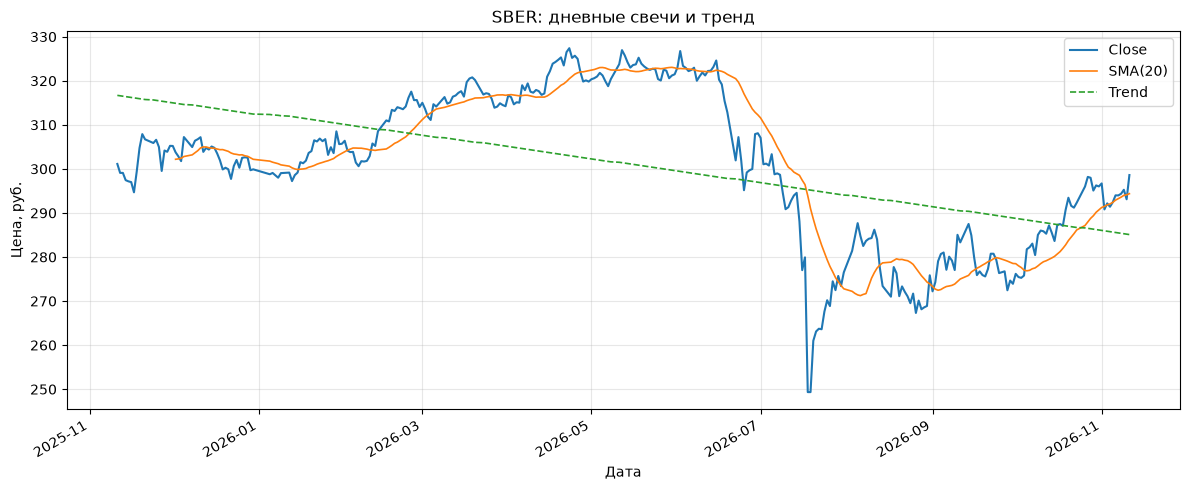

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["time"], df["close"], label="Close", linewidth=1.5)
ax.plot(df["time"], df["sma_20"], label="SMA(20)", linewidth=1.2)
ax.plot(df["time"], df["trend"], label=f"Trend", linestyle="--", linewidth=1.2)
ax.set_title(f"{TICKER}: дневные свечи и тренд")
ax.set_xlabel("Дата")
ax.set_ylabel("Цена, руб.")
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
